# ASTR 457: The Midterm

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

NETID = 'zahisr2'   # <-- set this
DATA = f'../../labs/midterm/data/{NETID}/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

## Part 1: Error bars (30 pts, 6 each)

### 1a - The extinction coefficient (`p1a_extinction.csv`)

An observer measured a photometric zero point at 15 different airmasses through one night. Extinction in magnitudes grows in proportion to the airmass $X$, so the zero point should follow a line, $m = k\,X + m_0$, where $k$ is the extinction coefficient in mag per airmass. Columns: `airmass`, `zeropoint_mag`, `sigma_quoted_mag` (the pipeline's error on each point).

1. Fit the line by weighted least squares with the quoted errors. Report $k$ and its error bar computed from the quoted errors alone.
2. Now run `np.polyfit(airmass, zeropoint_mag, 1, w=1/sigma_quoted_mag, cov=True)` and report its error bar on $k$. Explain exactly what `polyfit` did to get a different number (read its documentation for `cov`).
3. Compute $\chi^2$ and the number of degrees of freedom. How probable is a $\chi^2$ this large or this small if the quoted errors were right? (Compute it from the $\chi^2$ distribution.)
4. Report the error bar on $k$ you'd quote, and justify it. What does your answer to (3) tell you about the pipeline's error bars?

In [4]:
# 1a: your work here
d = load('p1a_extinction')
X = d['airmass'].to_numpy()
y = d['zeropoint_mag'].to_numpy()
sig = d['sigma_quoted_mag'].to_numpy()
N = len(X)

A = np.column_stack([X, np.ones(N)])           
w = 1 / sig**2                                  
cov_q = np.linalg.inv(A.T @ (A * w[:, None]))   
k, m0 = cov_q @ (A.T @ (w * y))                 
k_err = np.sqrt(cov_q[0, 0])                    
print('k =', round(k, 3), '+/-', round(k_err, 3), 'mag/airmass')
print('m0 =', round(m0, 3), '+/-', round(np.sqrt(cov_q[1, 1]), 3), 'mag')

k = 0.098 +/- 0.011 mag/airmass
m0 = 24.973 +/- 0.018 mag


In [5]:
p, cov_p = np.polyfit(X, y, 1, w=1/sig, cov=True)
print('polyfit k =', round(p[0], 3), '+/-', round(np.sqrt(cov_p[0, 0]), 3), 'mag/airmass')
print('polyfit m0 =', round(p[1], 3), '+/-', round(np.sqrt(cov_p[1, 1]), 3), 'mag')

p_u, cov_u = np.polyfit(X, y, 1, w=1/sig, cov='unscaled')
print('polyfit unscaled k_err =', round(np.sqrt(cov_u[0, 0]), 3), 'mag/airmass')

polyfit k = 0.098 +/- 0.023 mag/airmass
polyfit m0 = 24.973 +/- 0.039 mag
polyfit unscaled k_err = 0.011 mag/airmass


In [ ]:
resid = (y - (k * X + m0)) / sig                
chi2 = np.sum(resid**2)
dof = N - 2                                    
p_small = stats.chi2.cdf(chi2, dof)             
p_large = stats.chi2.sf(chi2, dof)             
print('chi2 =', round(chi2, 3), ' dof =', dof, ' chi2/dof =', round(chi2 / dof, 3))
print('P(chi2 <= this) =', p_small, ' P(chi2 >= this) =', p_large)

chi2 = 60.83  dof = 13  chi2/dof = 4.679
P(chi2 <= this) = 0.9999999626893077  P(chi2 >= this) = 3.7310692276629833e-08
scale = sqrt(chi2/dof) = 2.163
check: k_err * scale = 0.023


Explanation of polyfit vs. hand-written uncertainty on k down below.

scale = sqrt(chi2/dof) = 2.163
check: k_err * scale = 0.023


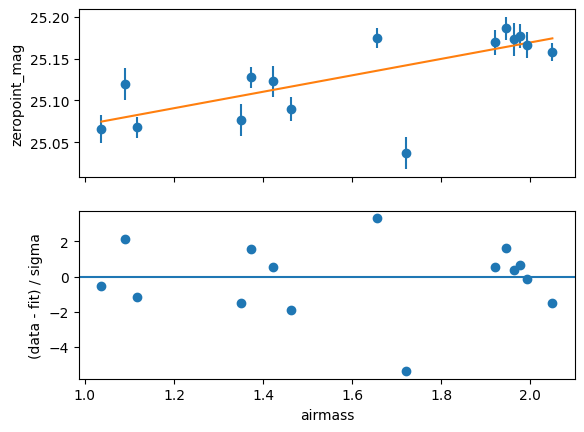

In [16]:
xx = np.linspace(X.min(), X.max(), 100)

print('scale = sqrt(chi2/dof) =', round(np.sqrt(chi2 / dof), 3))
print('check: k_err * scale =', round(k_err * np.sqrt(chi2 / dof), 3))

fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].errorbar(X, y, sig, fmt='o')
ax[0].plot(xx, k * xx + m0)
ax[0].set_ylabel('zeropoint_mag')
ax[1].axhline(0)
ax[1].plot(X, resid, 'o')
ax[1].set_ylabel('(data - fit) / sigma')
ax[1].set_xlabel('airmass')
plt.show()

**ANSWER:**

Our piplelines error bars are underestimated greatly as shown in question 3, as the probability that we recieved a scatter as large as we did (chi2 of 60.8) was near zero assuming our error bars for chi2 were correct. This chi squared test tells us that the error bars we reported were initially too small, and by re-arranging the chi2 equation we can see that the residuals are actually around 2.16 times larger than the quoted sigmas. 

Since 0.011 from WLS was an underestimate of the true uncertainty on k, we can multiply by the factor above to get a better estimate of uncertainty that np.polyfit was able to achieve by doing this: *0.023*.

### 1b - The centroid (`p1b_centroid.csv`)

A classmate measured the position of a star from `n_photons` photons, each landing at a position drawn from a Gaussian of width `psf_sigma_arcsec` around the true position. They report an error on the position of `quoted_sigma_x0_arcsec`, from a clever weighting scheme they found online.

1. Compute the Cramér-Rao bound on the error of any unbiased estimator of the position (Lab 02).
2. Is the quoted error possible? If not, say what the classmate's number must mean instead, and name two concrete mistakes that would produce an error bar this small.

In [17]:
# 1b: your work here
d = load('p1b_centroid')
print(d)

   psf_sigma_arcsec  n_photons  quoted_sigma_x0_arcsec
0           1.27528        288                0.044799


In [41]:
N = d['n_photons'].to_numpy()[0]
psf_sigma = d['psf_sigma_arcsec'].to_numpy()[0]
quoted_err = d['quoted_sigma_x0_arcsec'].to_numpy()[0]

bound = psf_sigma / np.sqrt(N)
print('N =', N, ' psf_sigma =', f'{psf_sigma:.3g}', 'arcsec')
print('CM bound =', f'{bound:.3g}', 'arcsec')
print('quoted_err =', f'{quoted_err:.3g}', 'arcsec')
print('quoted_err / bound =', f'{quoted_err / bound:.3g}')\

# check what N needs to be to get the quoted_err
N_estimated = (psf_sigma / quoted_err)**2
print('photons estimated =', f'{N_estimated:.3g}')

N = 288  psf_sigma = 1.28 arcsec
CM bound = 0.0751 arcsec
quoted_err = 0.0448 arcsec
quoted_err / bound = 0.596
photons estimated = 810


In [44]:
# check simulate for quoted_err from cr bound
rng = np.random.default_rng(0)
means = np.array([rng.normal(0, psf_sigma, int(N)).mean() for _ in range(2000)])
print('scatter of 2000 simulated position estimates =', f'{means.std():.3g}', 'arcsec - CR bound at 0.0751 arcsec')

scatter of 2000 simulated position estimates = 0.0749 arcsec - CR bound at 0.0751 arcsec


**ANSWER:**

Given the Cramer-Rao bound of 0.0749 arcseconds, my peers result of 0.044799 is implausible for an unbiased estimator. The equation of this bound is: uncertainty = psf_sigma / sqrt(N), which are measured values. 

To get an error bar this small, two mistakes that could produce this has to do with an incorrect psf_sigma or N. Rearranging and solving for the N and psf_sigma they would have used: (1.275 / 0.0448)^2 = 810 photons [N] --- 0.0448 × sqrt(288) = 0.760 (psf_sigma).

### 1c - The transit depth's error bar (`p1c_profile.csv`)

A transit-depth fit produced this profile: columns `depth_ppt` (the depth, in parts per thousand) and `minus2lnL` ($-2\ln L$ at that depth, other parameters fixed at their best values). A classmate took the second derivative of `minus2lnL` at its minimum and reported $\sigma = 1/\sqrt{d^2(-2\ln L)/d\,\textrm{depth}^2}$.

1. Find the best depth and the correct $1\sigma$ error from the curvature. Is the classmate's error bar right? If not, by what factor is it off, and why?
2. Read the $\Delta(-2\ln L) = 1$ interval directly off the profile. Is it symmetric? Compare it with your curvature answer.
3. If the classmate quotes $\pm$ their $\sigma$ on many independent datasets, what fraction of those intervals contain the true depth? Predict it, then check it with a simulation (a few thousand fake best-fit depths drawn around a truth you choose, using your correct $\sigma$).

81 points, depth from 1.422 to 4.099 ppt


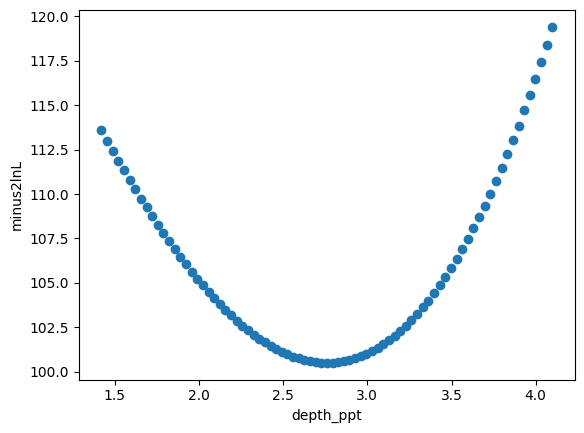

In [68]:
# 1c: your work here
d = load('p1c_profile')
x = d['depth_ppt'].to_numpy()
y = d['minus2lnL'].to_numpy()
print(len(x), 'points, depth from', round(x.min(), 3), 'to', round(x.max(), 3), 'ppt')

plt.plot(x, y, 'o')
plt.xlabel('depth_ppt')
plt.ylabel('minus2lnL')
plt.show() #parabolic

In [67]:
i = y.argmin()
best = x[i]
ymin = y[i]
near = (y - ymin) < 1
a, b, c = np.polyfit(x[near], y[near], 2)
second_deriv = 2 * a
sigma_correct = np.sqrt(2 / second_deriv)
sigma_class = 1 / np.sqrt(second_deriv)

print('Best Depth =', round(best, 3), 'ppt', '--- Best minus2lnL =', round(ymin, 3))
print('\nCorrect Sigma =', round(sigma_correct, 3), 'ppt')
print('Classmate Sigma =', round(sigma_class, 3), 'ppt')
print('\nClassmate / Correct =', round(sigma_class / sigma_correct, 3), '--- 1/sqrt(2) =', round(2**-0.5, 3))

Best Depth = 2.76 ppt --- Best minus2lnL = 100.495

Correct Sigma = 0.336 ppt
Classmate Sigma = 0.237 ppt

Classmate / Correct = 0.707 --- 1/sqrt(2) = 0.707


The best depth is 2.70 parts per thousand with minus2lnL of 100.495. Using polyfit we can find the second derivative of the quadratic fit to be 2*a easily (for a**2x + bx + c), and from the gaussian estimation and -2lnL = constant + (x - best)^2 / sigma^2, we find that the real sigma to be 0.336, while the classmate reports 0.237 which is off by a square root of 2. They must have left out the 2 in minus2lnL.

lower arm = 0.343  upper arm = 0.327  average arm = 0.335
Symmetry: Low to Middle = 0.343 ---- Middle to High = 0.327


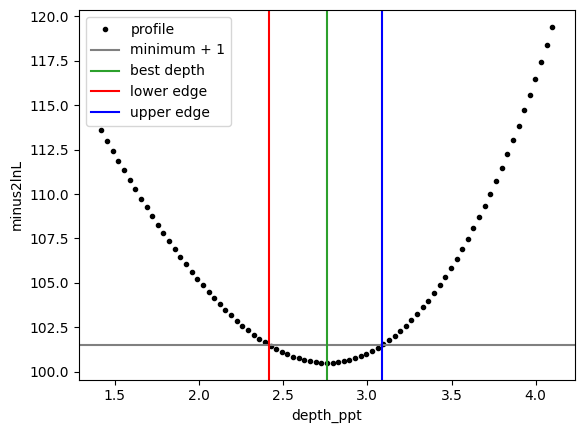

In [85]:
lo = np.interp(ymin + 1, y[:i + 1][::-1], x[:i + 1][::-1])
hi = np.interp(ymin + 1, y[i:], x[i:])
print('lower arm =', round(best - lo, 3), ' upper arm =', round(hi - best, 3), ' average arm =', round((hi - lo) / 2, 3))
print(f'Symmetry: Low to Middle = {round(best - lo, 3)} ---- Middle to High = {round(hi - best, 3)}')
plt.plot(x, y, 'o', ms=3, color='black', label='profile')
plt.axhline(ymin + 1, color='gray',  label='minimum + 1')
plt.axvline(best, color='tab:green', label='best depth')
plt.axvline(lo, color='red', label='lower edge')
plt.axvline(hi, color='blue', label='upper edge')
plt.xlabel('depth_ppt')
plt.ylabel('minus2lnL')
plt.legend()
plt.show()

The interval plotted above shows that the interval is not perfectly symmetric as the distance between the lowest bound to the midpoint is slightly larger than the midpoint to the upper bound. This may be due to the fact that the true data may not be perfectly modeled as a parabola.

In [53]:
r = sigma_class / sigma_correct
print('predicted fraction =', round(stats.norm.cdf(r) - stats.norm.cdf(-r), 3))
rng = np.random.default_rng(0)
fits = rng.normal(best, sigma_correct, 5000)
print('simulated fraction, classmate sigma =', round(np.mean(np.abs(fits - best) < sigma_class), 3))
print('simulated fraction, correct sigma =', round(np.mean(np.abs(fits - best) < sigma_correct), 3))

predicted fraction = 0.52
simulated fraction, classmate sigma = 0.517
simulated fraction, correct sigma = 0.677


We get the predicted fraction by using a gaussian of mean 0.366, and seeing the probability that an estimate lands within 0.237 (classmate answer) of that true mean which as proved in question 1 is 1/sqrt(2) sigma which is 52% of the gaussian. After simulating 5,000 trials, the simulated fraction is close to our prediction of 0.52, and using the correct sigma it caputures the true depth around 68% of times.

### 1d - The companion mass (`p1d_mass_samples.csv`)

These are 8000 posterior samples of the mass of an unseen companion, `M2_Msun`. Three classmates report its uncertainty as (i) the variance of the samples, (ii) the 84th percentile minus the 16th, and (iii) the standard deviation divided by $\sqrt{8000}$.

1. Report the mass as a median with its 16th-84th percentile error bars, in solar masses.
2. For each of (i)-(iii): what quantity is it actually, what are its units, and by roughly what factor is it wrong as a $1\sigma$ error bar?
3. Is a symmetric $\pm$ error bar appropriate for this posterior? If not, show why.

8000 samples, from 3.534 to 11.998 solar masses


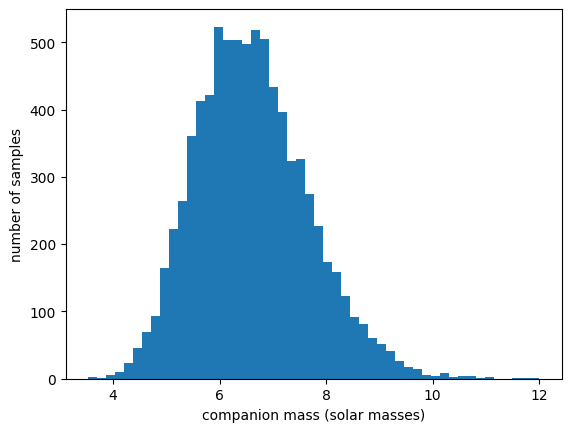

In [101]:
# 1d: your work here
d = load('p1d_mass_samples')
m = d['M2_Msun'].to_numpy()
print(len(m), 'samples, from', round(m.min(), 3), 'to', round(m.max(), 3), 'solar masses')

plt.hist(m, 50)
plt.xlabel('companion mass (solar masses)')
plt.ylabel('number of samples')
plt.show()

In [107]:
p16, p50, p84 = np.percentile(m, [16, 50, 84])
print(f'median = {round(p50, 3)}, 16th = {round(p16, 3)}, 84th = {round(p84, 3)} solar masses')
print(f'lower error bar = {round(p50 - p16, 3)}, upper error bar = {round(p84 - p50, 3)}')

median = 6.539, 16th = 5.577, 84th = 7.645 solar masses
lower error bar = 0.962, upper error bar = 1.107


In [106]:
sd = m.std(ddof=1)
half = (p84 - p16) / 2
var = sd**2
width = p84 - p16
sem = sd / np.sqrt(len(m))
print(f'1 sigma error bar (half of 84th - 16th) = {round(half, 3)} solar masses')
print(f'(i) variance = {round(var, 3)} solar masses squared; variance / error bar = {round(var / half, 3)}')
print(f'(ii) 84th - 16th = {round(width, 3)} solar masses; ratio = {round(width / half, 3)}')
print(f'(iii) std / sqrt(8000) = {round(sem, 4)} solar masses; ratio = {round(sem / half, 4)} 1 / ratio = {round(half / sem, 1)}')

1 sigma error bar (half of 84th - 16th) = 1.034 solar masses
(i) variance = 1.112 solar masses squared; variance / error bar = 1.075
(ii) 84th - 16th = 2.069 solar masses; ratio = 2.0
(iii) std / sqrt(8000) = 0.0118 solar masses; ratio = 0.0114 1 / ratio = 87.7


fraction below median - half = 0.14  fraction above median + half = 0.177
skewness = 0.489  mean = 6.616  median = 6.539


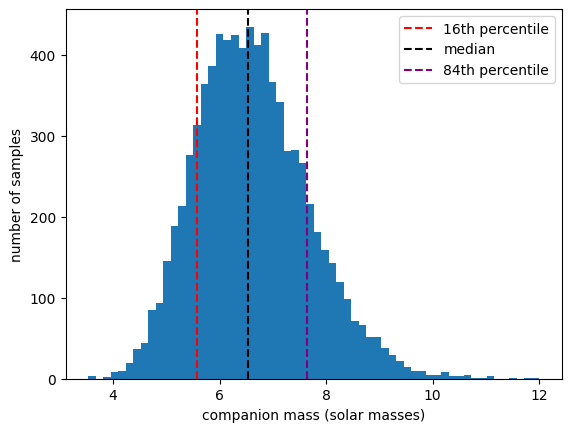

In [111]:
print('fraction below median - half =', round(np.mean(m < p50 - half), 3), ' fraction above median + half =', round(np.mean(m > p50 + half), 3))
print('skewness =', round(stats.skew(m), 3), ' mean =', round(m.mean(), 3), ' median =', round(p50, 3))

plt.hist(m, 60)
plt.axvline(p16, color='red', linestyle='--')
plt.axvline(p50, color='black', linestyle='--')
plt.axvline(p84, color='purple', linestyle='--')
plt.xlabel('companion mass (solar masses)')
plt.ylabel('number of samples')
plt.legend(['16th percentile', 'median', '84th percentile'])
plt.show()

No a symettric +- error bar is not adequate for the posterior because the distribution of companion masses are slightly right skew (skewed toward greater masses) which has the effect of increasing the upper error bar of 1.107 over the lower of 0.962.

### 1e - The slope at fixed intercept (`p1e_slope_intercept_samples.csv`)

Posterior samples of a slope and an intercept from a line fit. A classmate fixed the intercept at its best value, refit only the slope, and quoted the slope's error from that 1-D fit.

1. Compute the slope's error bar the classmate got (the spread of the slope *at fixed intercept*), and the marginal one (the spread of the slope with the intercept marginalized over).
2. Compute their ratio, and the correlation coefficient $\rho$ of the samples. How does the ratio depend on $\rho$? Plot the samples and draw both error bars on the plot.
3. When is the classmate's number the right one to quote? One sentence.

In [112]:
# 1e: your work here
d = load('p1e_slope_intercept_samples')
slope = d['slope'].to_numpy()
intercept = d['intercept'].to_numpy()

print(f'{len(slope)} samples')

6000 samples


In [115]:
sd_marg = slope.std(ddof=1)
rho = np.corrcoef(slope, intercept)[0, 1]
sd_cond = sd_marg * np.sqrt(1 - rho**2)

print(f'marginal slope error bar = {sd_marg:.4f}')
print(f'fixed-intercept slope error bar = {sd_cond:.4f}')
print(f'ratio fixed-intercept / marginal = {sd_cond / sd_marg:.3f}')
print(f'correlation rho = {rho:.3f}')

marginal slope error bar = 0.0218
fixed-intercept slope error bar = 0.0129
ratio fixed-intercept / marginal = 0.590
correlation rho = -0.807


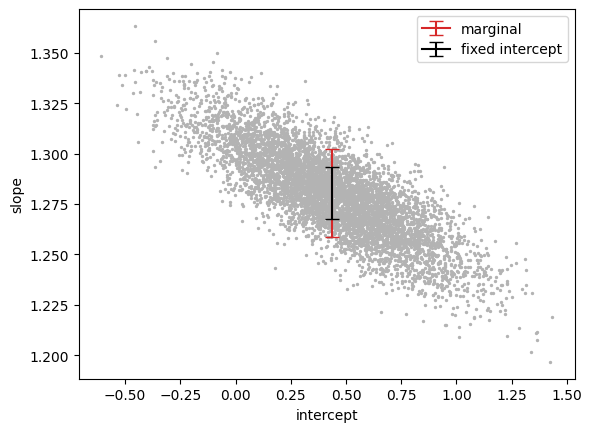

In [117]:
x0 = intercept.mean()
y0 = slope.mean()
plt.scatter(intercept, slope, s=2, color='0.7')
plt.errorbar(x0, y0, yerr=sd_marg, capsize=5, color='tab:red', label='marginal')
plt.errorbar(x0, y0, yerr=sd_cond, capsize=5, color='k', label='fixed intercept')
plt.xlabel('intercept')
plt.ylabel('slope')
plt.legend()
plt.show()

**ANSWER:**
As rho increases and approaches 1, the ratio goes toward zero which means that the classmates error bar will shrink toward zero while the true uncertainty of slope doesn't. The slope and intercept trade off resulting in the scatterplot above, forming a negatively sloped ellipse (pho = -.87). The classmate answer is correct only when we know the intercept exactly and if the slope and intercept are uncorrelated, but selecting the best intercept neglecting the uncertainty of that measurement is not justifiable enough.

## Part 2: 250 supernovae and a step (45 pts)

Type Ia supernovae are standardizable candles: their peak brightness, corrected for how fast they fade and for their color, measures distance well enough to have discovered cosmic acceleration. Your file `p2_pantheon_sne.csv` holds 250 real SNe Ia from the Pantheon+ compilation (Scolnic et al. 2022, ApJ 938, 113; [Brout et al. 2022](https://arxiv.org/abs/2202.04077), ApJ 938, 110), all at redshift $0.023 < z < 0.15$. For each supernova, a light-curve fit (SALT2) gives:

- `mB`: the peak apparent magnitude in the B band, and `mB_err`;
- `x1`: the light-curve *stretch* (broader light curves are brighter), and `x1_err`;
- `c`: the *color* (redder supernovae are fainter, from dust and intrinsically), and `c_err`;
- `cov_mB_x1`, `cov_mB_c`, `cov_x1_c`: the covariances between those three, from the same light-curve fit;
- `z`: the redshift; `host_logmass`, `host_logmass_err`: $\log_{10}$ of the host galaxy's stellar mass in solar masses, and its error.

The standardized brightness is the **Tripp relation**,

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$

where $M$ is the absolute magnitude of a "standard" SN Ia, $\mu(z)$ the distance modulus, $\Theta$ is 1 for hosts more massive than $10^{10}\,M_\odot$ and 0 otherwise, and $\gamma$ is the **host-mass step**. Supernovae in massive hosts appear to be brighter after standardization (Kelly et al. 2010; Sullivan et al. 2010); whether the step is real, and why, matters for supernova dark-energy measurements. In this form, a step that makes supernovae in massive hosts brighter has $\gamma < 0$; the published value is about $\gamma \approx -0.06$ mag. So the question for your sample is whether you need $\gamma$ at all.

There are two more things you'll need. At these redshifts the galaxies' own motions (peculiar velocities, about 250 km/s) shift $z$, and so $\mu$; add $\sigma_{\mu,\rm pec} = \frac{5}{\ln 10}\frac{250\ {\rm km/s}}{c\,z}$ to each supernova's variance. And no supernova is a perfect standard candle: add an intrinsic scatter $\sigma_{\rm int}$, a free parameter. Use a flat $\Lambda$CDM distance modulus with $H_0 = 70$ km/s/Mpc and $\Omega_m = 0.3$ (`astropy.cosmology.FlatLambdaCDM(H0=70, Om0=0.3).distmod(z)`); $M$ absorbs the choice of $H_0$.

We planted between **two and four contaminants** in your file - objects whose `mB` we made fainter by more than a magnitude, so they are not standard SNe Ia any more (think of a mis-classified peculiar supernova). Their names are not in the file. Real data have a few real outliers too, so not everything far from the line is planted.

### 2a - Look at the data (5 pts)

1. Compute $\mu(z)$ and plot the **Hubble residuals** $m_B - \mu(z)$ against $x_1$, against $c$, and against `host_logmass`.
2. Which way do the $x_1$ and $c$ trends go? Is that the sign the Tripp relation expects? Two or three sentences.
3. The raw trend with host mass may not have the sign of $\gamma$. Why not? (Plot $x_1$ against host mass.)
4. Can you see any of the contaminants?
5. What units do $\alpha$ and $\beta$ have?

In [124]:
# 2a: your work here
from astropy.cosmology import FlatLambdaCDM

d = load('p2_pantheon_sne')
z = d['z'].to_numpy()
mB = d['mB'].to_numpy()
x1 = d['x1'].to_numpy()
c = d['c'].to_numpy()
mass = d['host_logmass'].to_numpy()

mu = FlatLambdaCDM(H0=70, Om0=0.3).distmod(z).value
resid = mB - mu

print(f'slope of residual vs x1 = {np.polyfit(x1, resid, 1)[0]:.3f} magnitudes per unit x1')
print(f'slope of residual vs c = {np.polyfit(c, resid, 1)[0]:.3f} magnitudes per magnitude of color')
print(f'correlation of x1 with host mass = {np.corrcoef(x1, mass)[0, 1]:.3f}')

slope of residual vs x1 = -0.164 magnitudes per unit x1
slope of residual vs c = 2.897 magnitudes per magnitude of color
correlation of x1 with host mass = -0.416


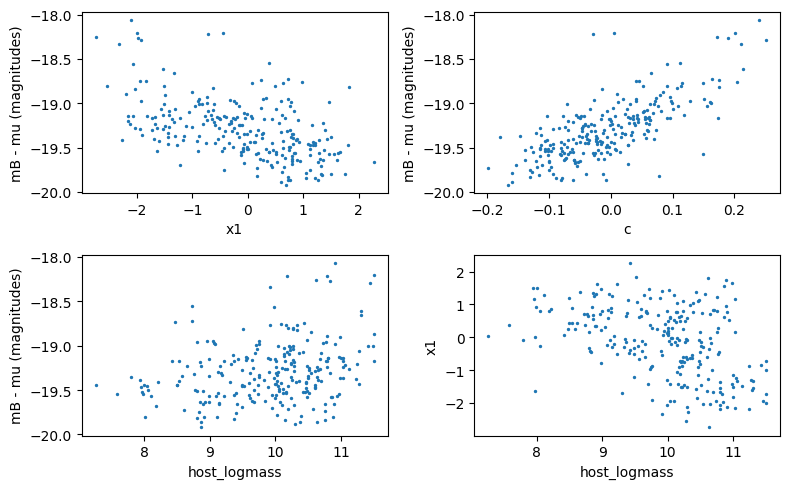

In [129]:
fig, ax = plt.subplots(2, 2, figsize=(8,5))
ax[0, 0].scatter(x1, resid, s=2)
ax[0, 0].set_xlabel('x1')
ax[0, 0].set_ylabel('mB - mu (magnitudes)')

ax[0, 1].scatter(c, resid, s=2)
ax[0, 1].set_xlabel('c')
ax[0, 1].set_ylabel('mB - mu (magnitudes)')

ax[1, 0].scatter(mass, resid, s=2)
ax[1, 0].set_xlabel('host_logmass')
ax[1, 0].set_ylabel('mB - mu (magnitudes)')

ax[1, 1].scatter(mass, x1, s=2)
ax[1, 1].set_xlabel('host_logmass')
ax[1, 1].set_ylabel('x1')

plt.tight_layout()
plt.show()

Tripp Relation: $$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$
$$residual = m_B - mu(z) = M + \ - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$


2. As x1 rises, the residual decreases, and as c rises, the residual incraeses. This is predicted by the tripp relation as the residual is M - alpha x1 + beta c, so with positive alpha and beta; as X1 increases, M decreases (brighter), and as C increases, M increases (dimmer).

3. The correlation between x1 and the host mass is -0.416 meaning as host_logmass increases, x1 decreases. If you lower the stretch of the light curve increasing massive hosts, the gamma would make the hosts brighter so the brightening and dimming effects cancel.

4. 



**ANSWER:**

*your answer goes here*

### 2b - The likelihood (10 pts)

The parameters are $\theta = (M, \alpha, \beta, \gamma, \sigma_{\rm int})$. Each supernova's variance is

$$\sigma_i^2 = \mathbf{v}^T C_i\,\mathbf{v} + \sigma_{\mu,{\rm pec},i}^2 + \sigma_{\rm int}^2, \qquad \mathbf{v} = (1, \alpha, -\beta),$$

where $C_i$ is that supernova's $3\times3$ covariance of $(m_B, x_1, c)$.

1. Write out $\mathbf{v}^T C_i\,\mathbf{v}$ term by term, and explain in one sentence why the off-diagonal terms are there.
2. Write the log-likelihood. Remember the $\ln\sigma_i^2$ term - the variance depends on the parameters.
3. State a prior for every parameter, and justify each in one line.
4. Decide whether to sample $\ln\sigma_{\rm int}$ or $\sigma_{\rm int}$, and say why.
5. Decide what to do about the contaminants. You may model them or remove them, but say how you found them and what a cut would cost you.

In [ ]:
# 2b: your work here

**ANSWER:**

*your answer goes here*

### 2c - Sampling and convergence (12 pts)

1. Find the maximum a posteriori point. Then run **four independent chains** from starting points spread wider than the posterior (you choose how, and say how you chose). Any sampler is fine - your own Metropolis, `emcee` (one ensemble per chain), or `PyMC`.
2. Report $\hat R$ and the effective sample size for every parameter (`arviz.rhat`, `arviz.ess`, or `arviz.summary`), and say what values would have made you run longer.
3. Make a corner plot, and quote $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 16th-84th percentile error bars.
4. Which parameters are correlated strongly? Comment on why. Then fix $M$ at its MAP value, refit $\gamma$, and compare that $\sigma_\gamma$ with the marginal one (cf. 1e).

`ArviZ` 1.x (install it with `conda install -c conda-forge pymc arviz`, as in `INSTALL.txt`) takes your chains as a dictionary of arrays shaped (chain, draw): `idata = az.from_dict({'posterior': {'alpha': a, 'beta': b}})`, then `az.summary(idata)`.

In [ ]:
# 2c: your work here

**ANSWER:**

*your answer goes here*

### 2d - Model comparison (10 pts)

Compare $M_0$ ($\gamma = 0$) with $M_1$ ($\gamma$ free).

1. Compute $2\ln B_{1,0}$ with the Laplace approximation (Day 13), with a prior on $\gamma$ you state and defend. How does it change if that prior is twice as wide?
2. Compute $\textrm{BIC}_0 - \textrm{BIC}_1$ for comparison.
3. How strong is your answer on Day 8's scale (0-2 weak, 2-6 positive, 6-10 strong, above 10 very strong)? Compare $\gamma$ with the published $-0.06$ mag. Could your 250 supernovae have detected a step that size? (One way: your $\sigma_\gamma$ tells you how many $\sigma$ a $-0.06$ step would be.)

In [ ]:
# 2d: your work here

**ANSWER:**

*your answer goes here*

### 2e - Testing your pipeline (8 pts)

Design one test of your pipeline that would come out differently if your pipeline were wrong, and run it. State **before** you run it what result would count as a failure. One suggestion: generate fake supernovae at your redshifts, stretches and colors from parameters you choose (including a $\gamma$ you choose), fit 30 or more such datasets (maximum-likelihood fits with curvature error bars are fine here; you don't need MCMC for each), and check how often your 68% intervals contain the truth.

In [ ]:
# 2e: your work here

**ANSWER:**

*your answer goes here*

## Part 3: The referee report (25 pts)

White dwarfs are the cores of dead stars like the Sun. Your file `p3_wd_masses.csv` holds 600 real DA (hydrogen-atmosphere) white dwarfs from the 100 pc sample of [Kilic et al. (2020)](https://arxiv.org/abs/2006.00323), ApJ 898, 84: `name`, `teff_K`, `mass_Msun`, `mass_err_Msun`. Most single white dwarfs have masses near $0.6\,M_\odot$; Kilic et al. report a narrow peak there plus an excess of more massive ones, around $0.7$-$0.9\,M_\odot$, which merger products alone do not explain.

The notebook `labs/midterm/ai_solution.ipynb` fits your masses with a two-population model using `emcee`. Run it from that directory, after setting `NETID` in its first cell. It runs top to bottom and the plots look nice, but it's wrong in at least three substantive ways - and if you don't look at your data, you'll fool yourself the same way.

### 3a - The report (20 pts)

1. **Identify** at least three substantive errors (not style; "it used 32 walkers and I'd use 48" is not one).
2. **Demonstrate** each on *your* file: show, with a number or a plot, what the error does to the answer. A demonstration can come out negative: if an error doesn't move your numbers, show that, and say what it would take for it to matter.
3. **State** the correct treatment, and run it where you can.

In [ ]:
# 3a: your work here

**REFEREE REPORT:**

*your report goes here*

### 3b - AI-use appendix (5 pts)

1. Which tools did you use, for what, what did they get wrong, and how did you catch it? "I used ChatGPT to help" is useless; "none" is fine if that's true. I promise I don't care which - just be honest about what you did.
2. What would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing, in two or three sentences.

**AI-USE APPENDIX:**

*your answer goes here*